# Example 3 — Dark count rate (DCR)

The DCR map is each pixel's dark-count rate in counts per second:

```
DCR = counts / (nframes × n_files × live time per frame)
```

Full explanation: [Dark count rate](../docs/guide/dcr.md).

## What you need

- a folder of `.bin` files acquired **in the dark**, for example:
  - one quadrant in counting mode (`S0C`...`S3C`),
  - one quadrant in timestamping mode (`S0T`...`S3T`),
  - all four micropixels together (`ORC`, `ORT`);
- `nframes`, the frames per file you acquired with;
- the live time per frame, which depends on the firmware:
  - **`short_exposure`** (current firmware, the default): only the open shutter
    window is photon-sensitive. Pass the `open_shutter_time_s` the run used,
    because the data does not record it.
  - **`long_exposure`** (legacy firmware): the whole `exp_time_s + 9 µs` cycle is
    live.

What a count is follows from the last letter of the tag:

- `...C`: the per-frame photon counter;
- `...T`: frames carrying a valid timestamp, so at most one per pixel per frame.

## 1. Point dapkel at the data

In [1]:
import glob
import os

from IPython.display import Image, display


def show_figures(folder, kind):
    """Show the figures plot_* saved to results/<kind>/ (it closes them)."""
    for png in sorted(glob.glob(os.path.join(folder, "results", kind, "*.png"))):
        display(Image(filename=png))

In [2]:
import numpy as np

from dapkel.functions import dcr_analysis

path = r"D:\Kelpie\2026.08.07\22V"
nframes = 8192
tag = "S0T"
# tag = "ORC"
open_shutter_time_s = 8e-06

## 2. Compute and save the map

`process_dcr` unpacks the files and saves the `(32, 32)` map in cps to
`processed/<folder>_<tag>_dcr.npy` (tag lower-cased, e.g. `22V_s0t_dcr.npy`).
The sidecar records the frame count, the firmware and the live time. It prints
the median and maximum.

In [3]:
dcr_analysis.process_dcr(path, nframes, tag, open_shutter_time_s=open_shutter_time_s)


> > > Computing the 'S0T' DCR map (mode='timestamp') < < <



S0T:   0%|          | 0/100 [00:00<?, ?it/s]

S0T: 100%|██████████| 100/100 [01:05<00:00,  1.53it/s]

  ! timestamp mode saturates at 1.25e+05 cps; the hottest pixel is at 27% of that and 0 are past 50%, so those read low. Pass pileup_correct=True for the Poisson-corrected rate.
  median 117  max 34089 cps

> > > DCR map saved to D:\Kelpie\2026.08.07\22V\processed\22V_s0t_dcr.npy < < <


'D:\\Kelpie\\2026.08.07\\22V\\processed\\22V_s0t_dcr.npy'

On legacy firmware, give the exposure instead:

In [4]:
# dcr_analysis.process_dcr(path, nframes, tag,
#                          firmware_version="long_exposure", exp_time_s=10e-6)

## 3. Plot it

`plot_dcr` saves a heatmap and a sorted distribution (log scale, since DCR spans
decades) to `results/dcr/`, and returns the map.


> > > Plot is saved as 22V_s0t_dcr_heatmap.png in D:\Kelpie\2026.08.07\22V\results\dcr < < <

> > > Plot is saved as 22V_s0t_dcr_distribution.png in D:\Kelpie\2026.08.07\22V\results\dcr < < <


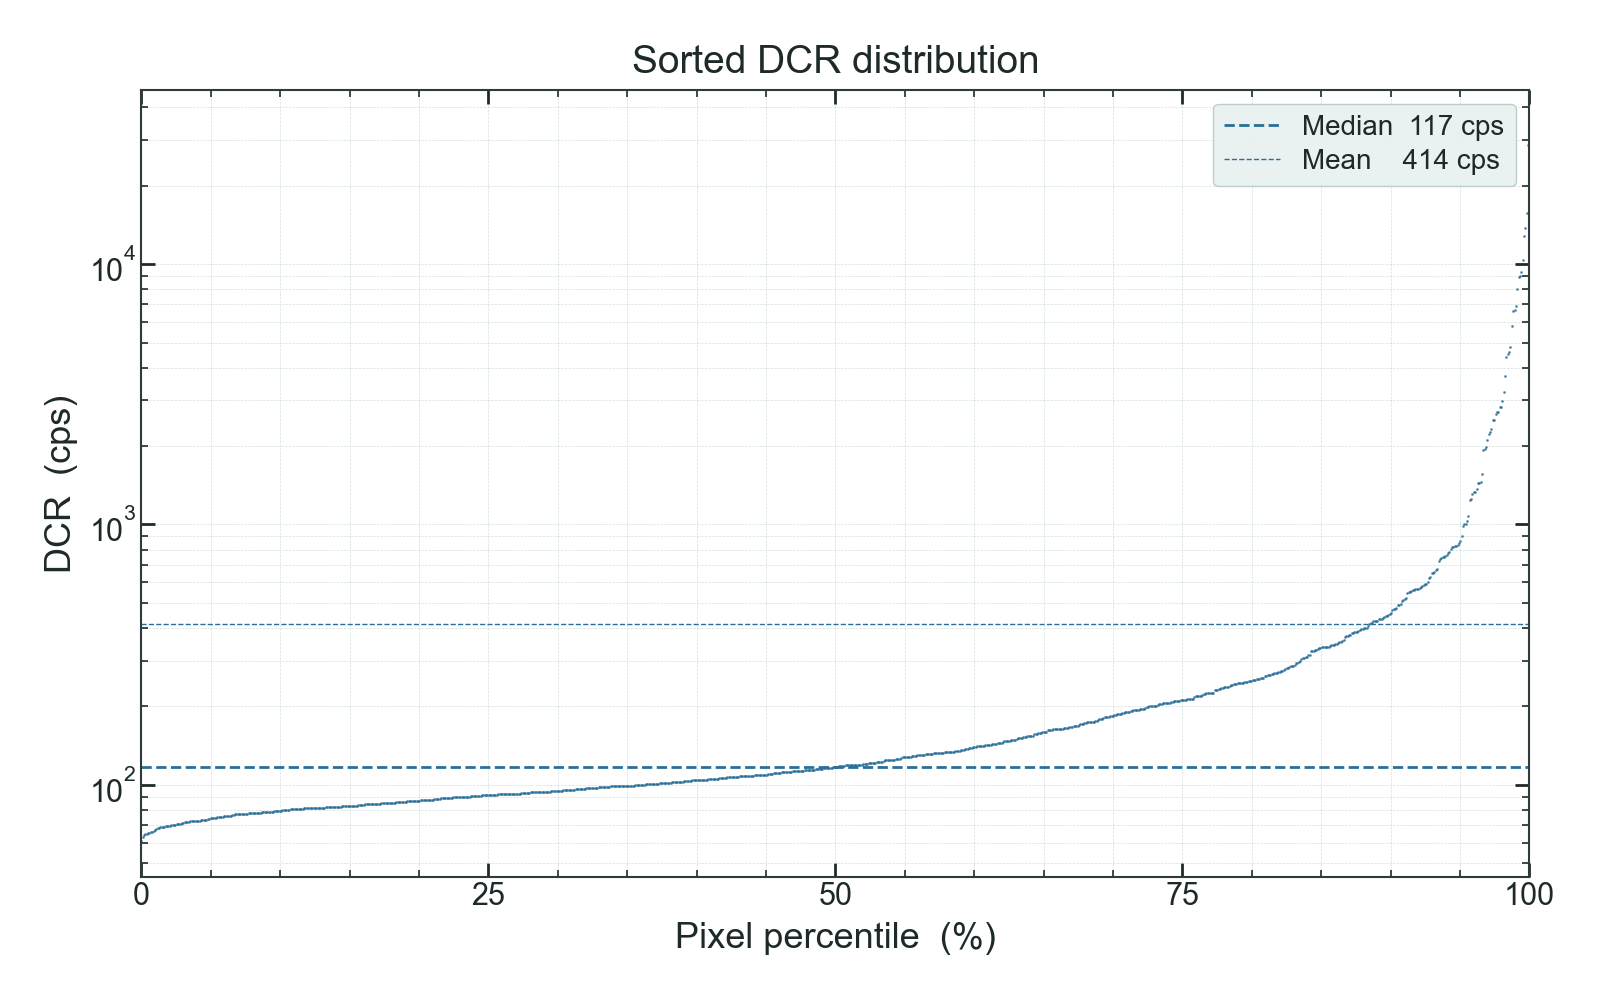

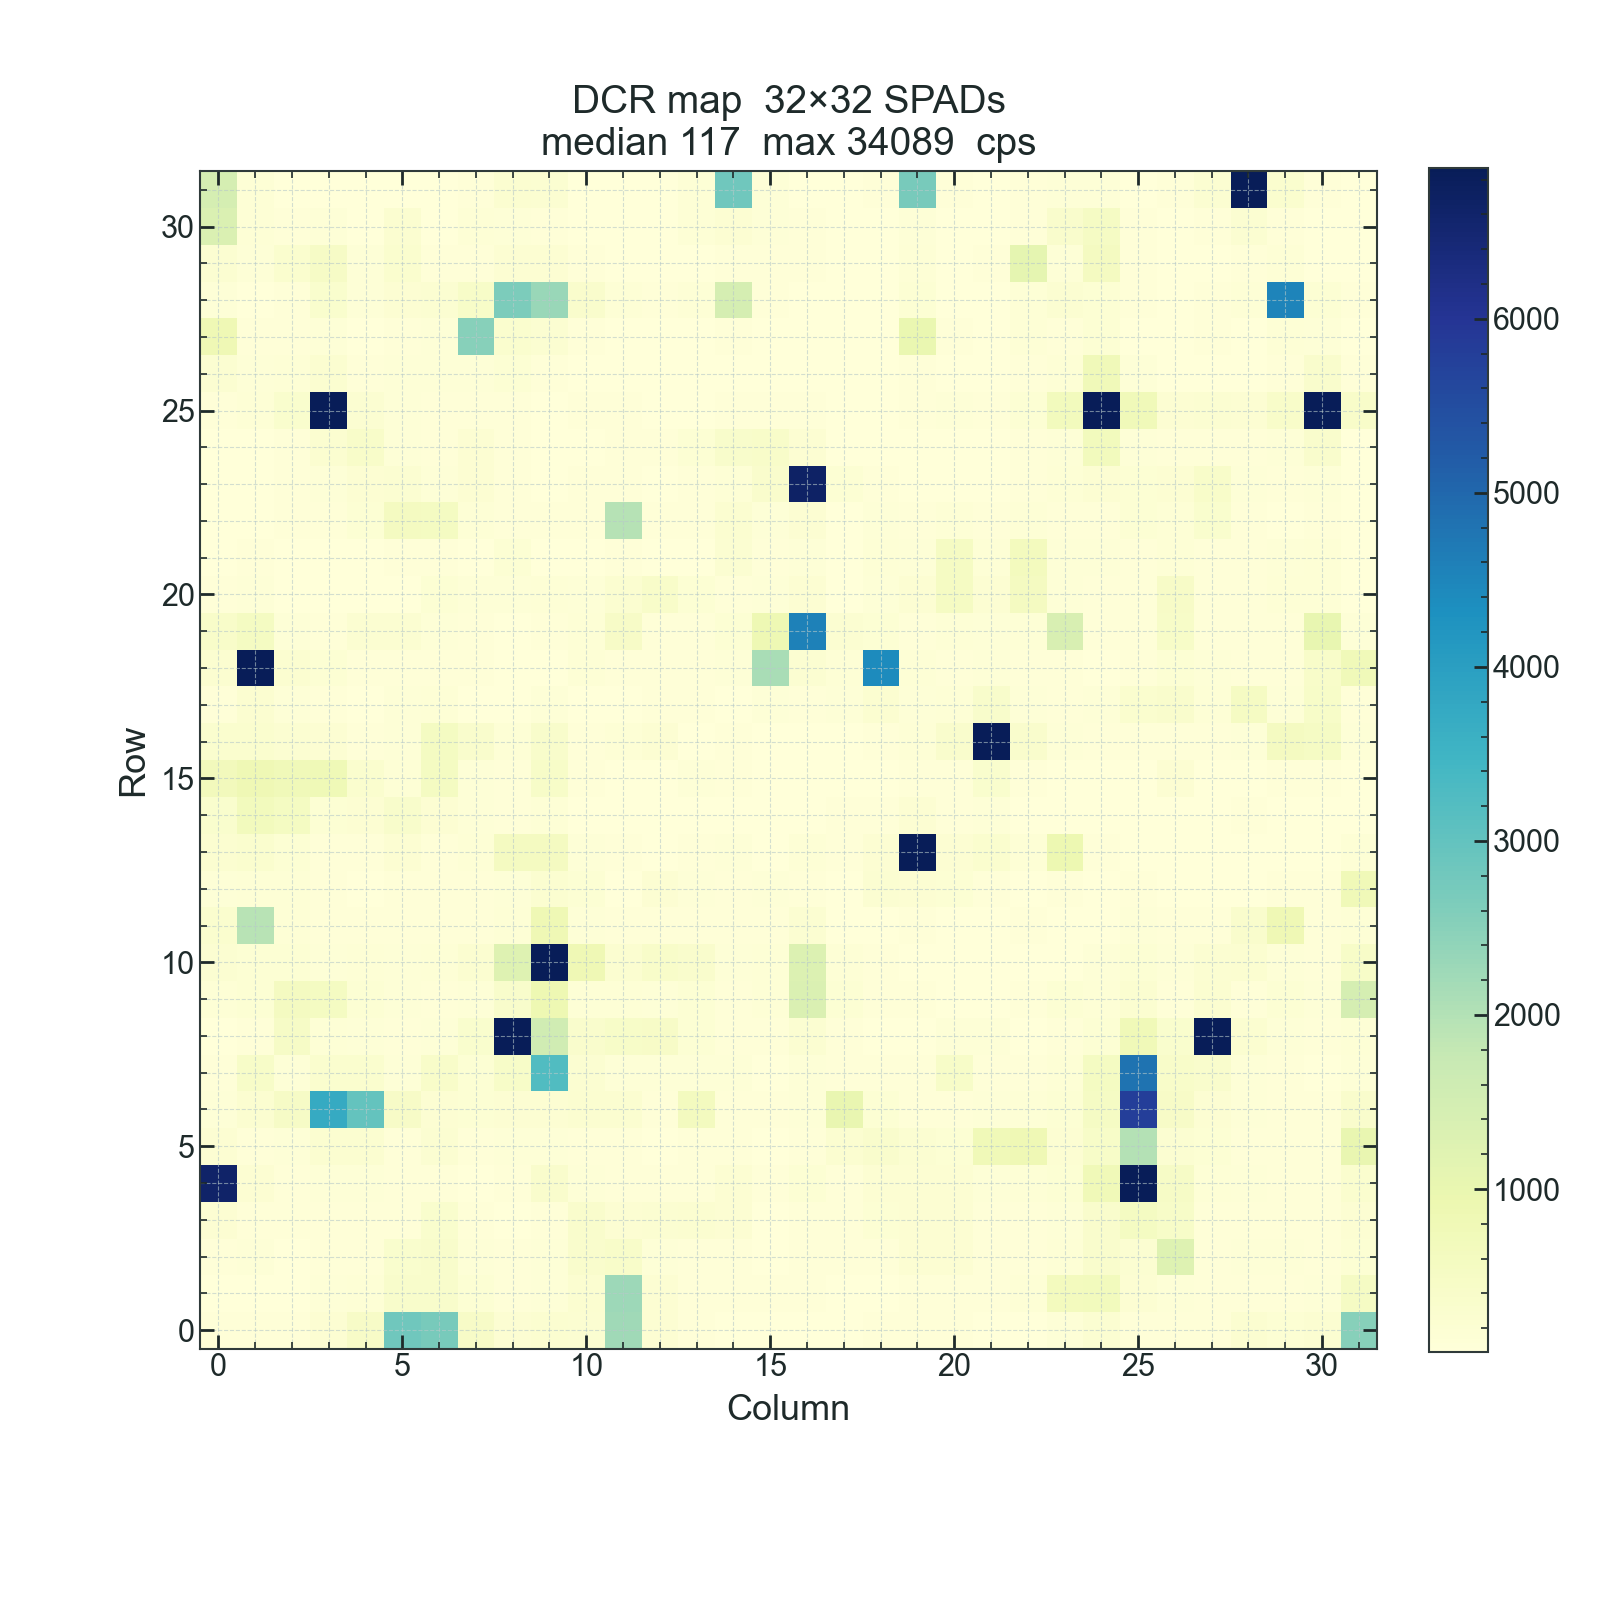

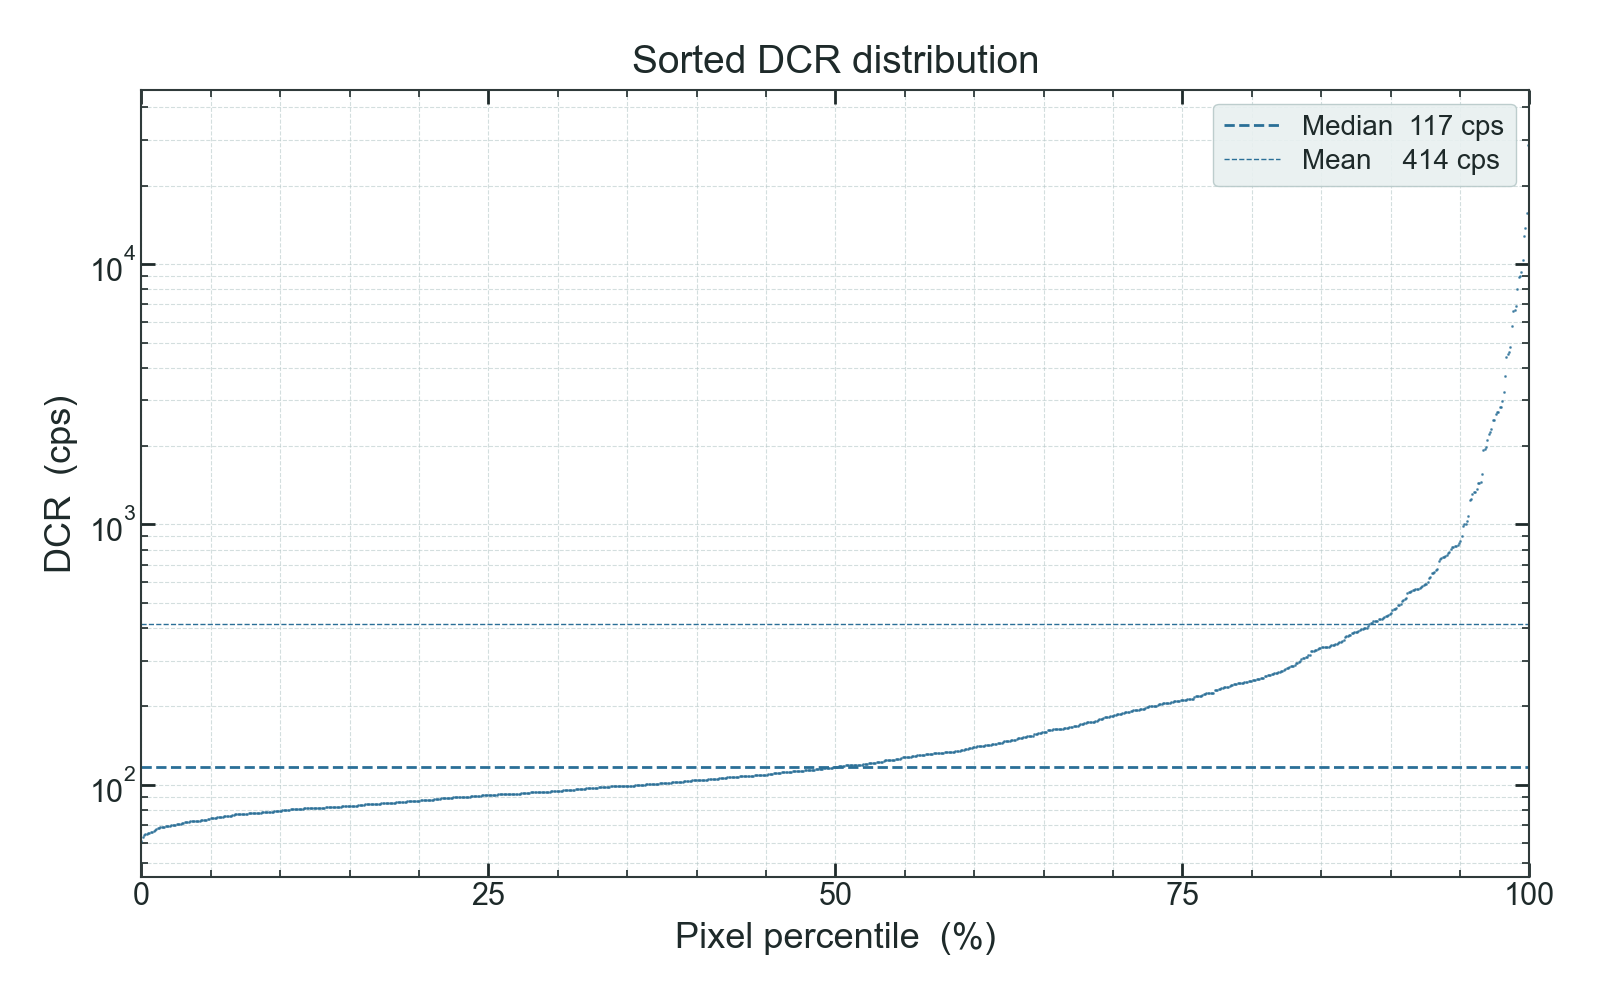

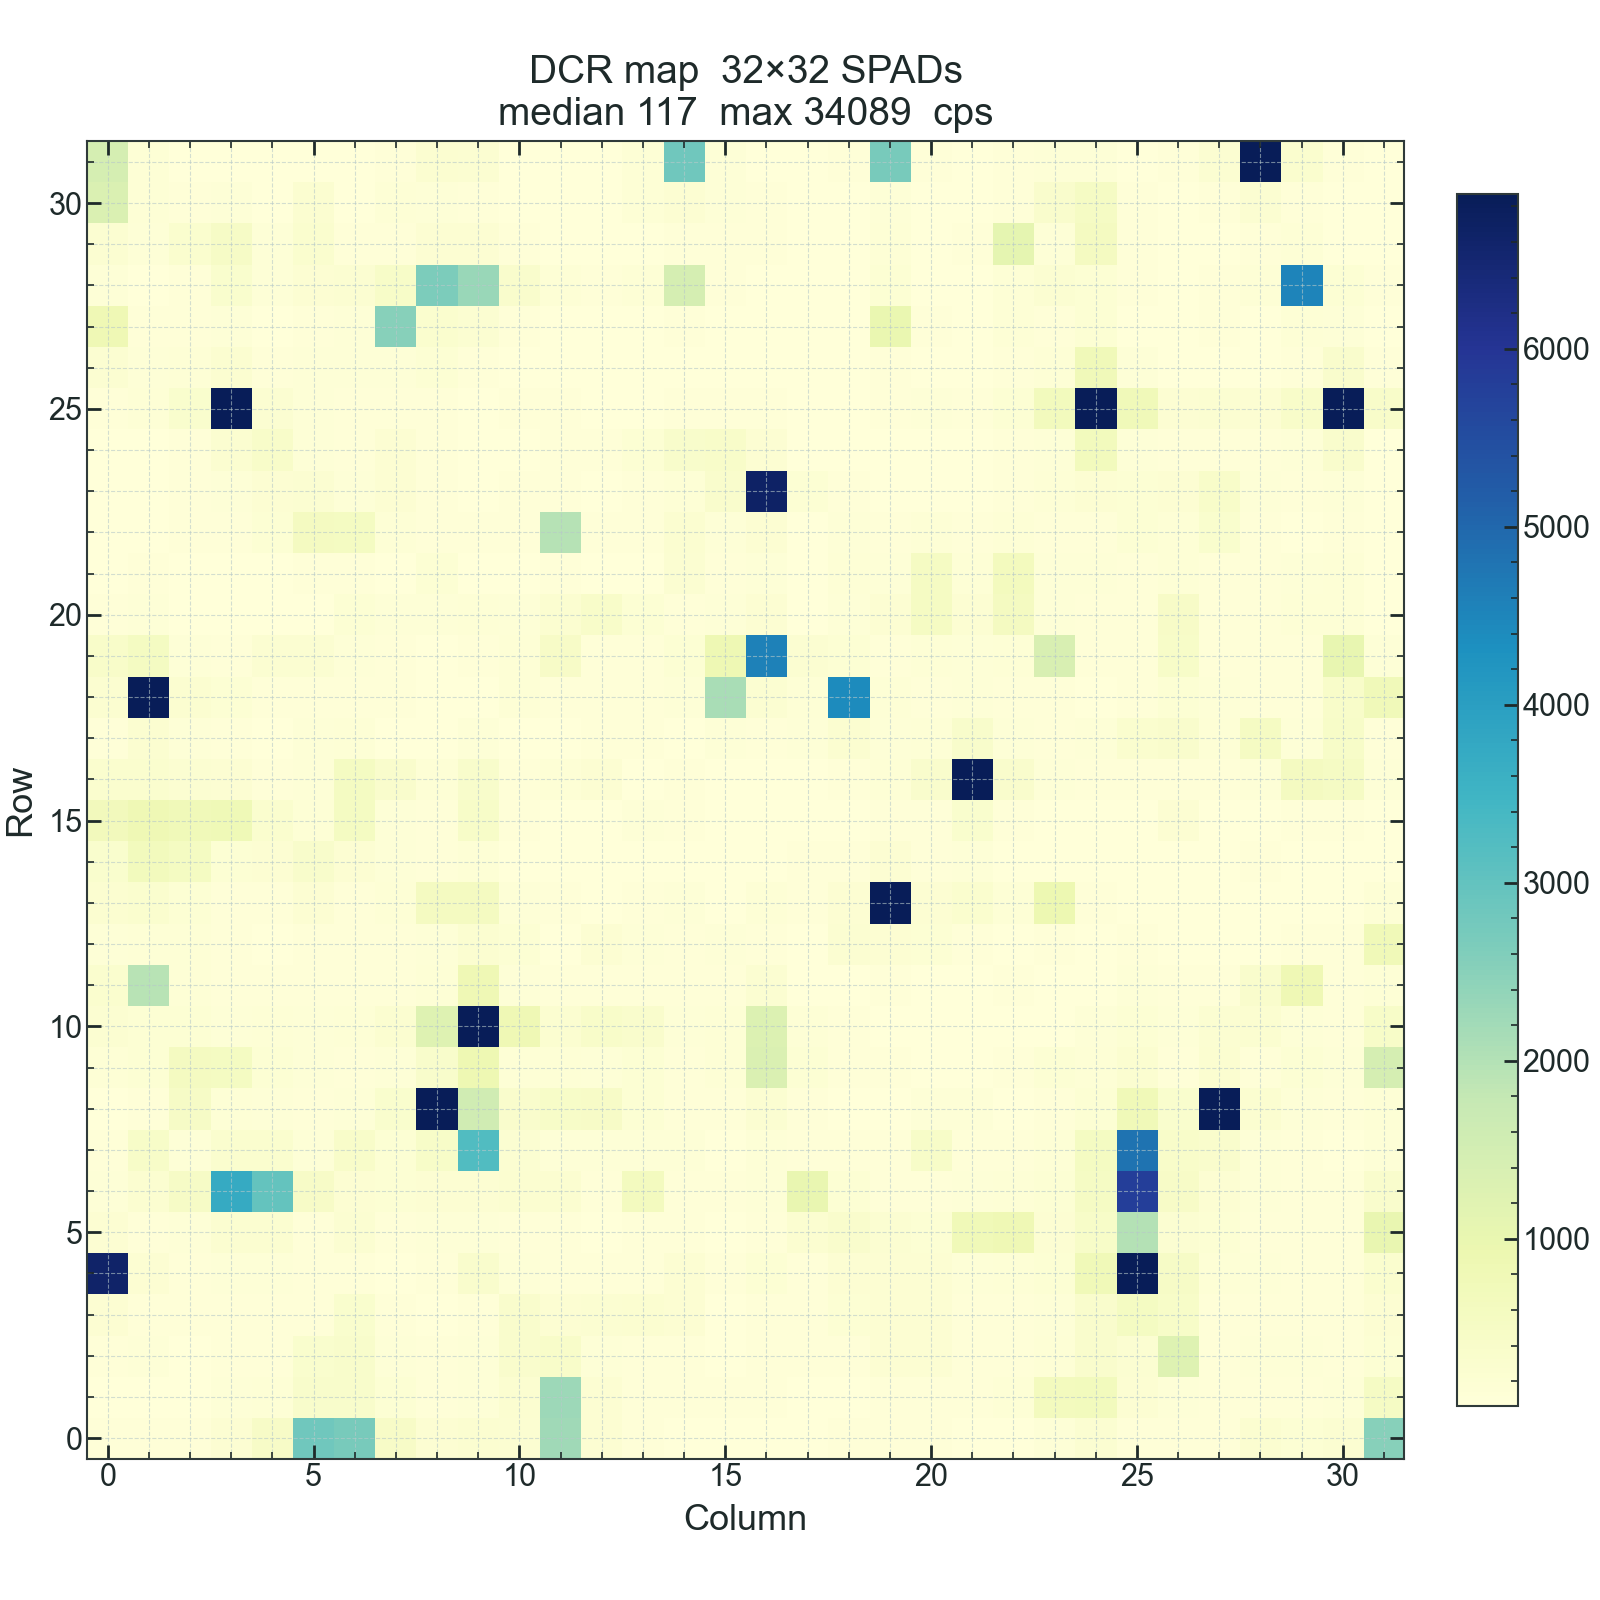

In [5]:
dcr = dcr_analysis.plot_dcr(path, tag)
# another colormap costs a load, not a re-read of the raw files:
# dcr = dcr_analysis.plot_dcr(path, tag, cmap="magma")
show_figures(path, "dcr")

## 4. Numbers from the map

The usual summary is the median plus the fraction of hot pixels. The threshold
below is only an example; pick yours.

In [6]:
print(f"median {np.nanmedian(dcr):.0f} cps, mean {np.nanmean(dcr):.0f} cps")
hot = dcr > 10 * np.nanmedian(dcr)
print(f"{hot.sum()} hot pixels ({hot.mean() * 100:.1f} %):", np.argwhere(hot).tolist())

median 117 cps, mean 414 cps
45 hot pixels (4.4 %): [[0, 5], [0, 6], [0, 11], [0, 31], [1, 11], [2, 26], [4, 0], [4, 25], [5, 25], [6, 3], [6, 4], [6, 25], [7, 9], [7, 25], [8, 8], [8, 9], [8, 27], [9, 16], [9, 31], [10, 8], [10, 9], [10, 16], [11, 1], [13, 19], [16, 21], [18, 1], [18, 15], [18, 18], [19, 16], [19, 23], [22, 11], [23, 16], [25, 3], [25, 24], [25, 30], [27, 7], [28, 8], [28, 9], [28, 14], [28, 29], [30, 0], [31, 0], [31, 14], [31, 19], [31, 28]]


## 5. Timestamping mode saturates — use `pileup_correct`

A `...T` program records at most one count per frame. So the raw rate is an
occupancy that saturates at `1 / open_shutter_time_s`, e.g. 125 kcps at an
8 µs shutter. It reads low well before that ceiling.

`process_dcr` warns when the hottest pixel passes 5 % of the ceiling.
`pileup_correct=True` inverts the censoring under Poisson statistics.


> > > Computing the 'S0T' DCR map (mode='timestamp') < < <



S0T: 100%|██████████| 100/100 [01:05<00:00,  1.53it/s]


  median 117  max 39805 cps

> > > DCR map saved to D:\Kelpie\2026.08.07\22V\processed\22V_s0t_dcr.npy < < <

> > > Plot is saved as 22V_s0t_dcr_heatmap.png in D:\Kelpie\2026.08.07\22V\results\dcr < < <

> > > Plot is saved as 22V_s0t_dcr_distribution.png in D:\Kelpie\2026.08.07\22V\results\dcr < < <


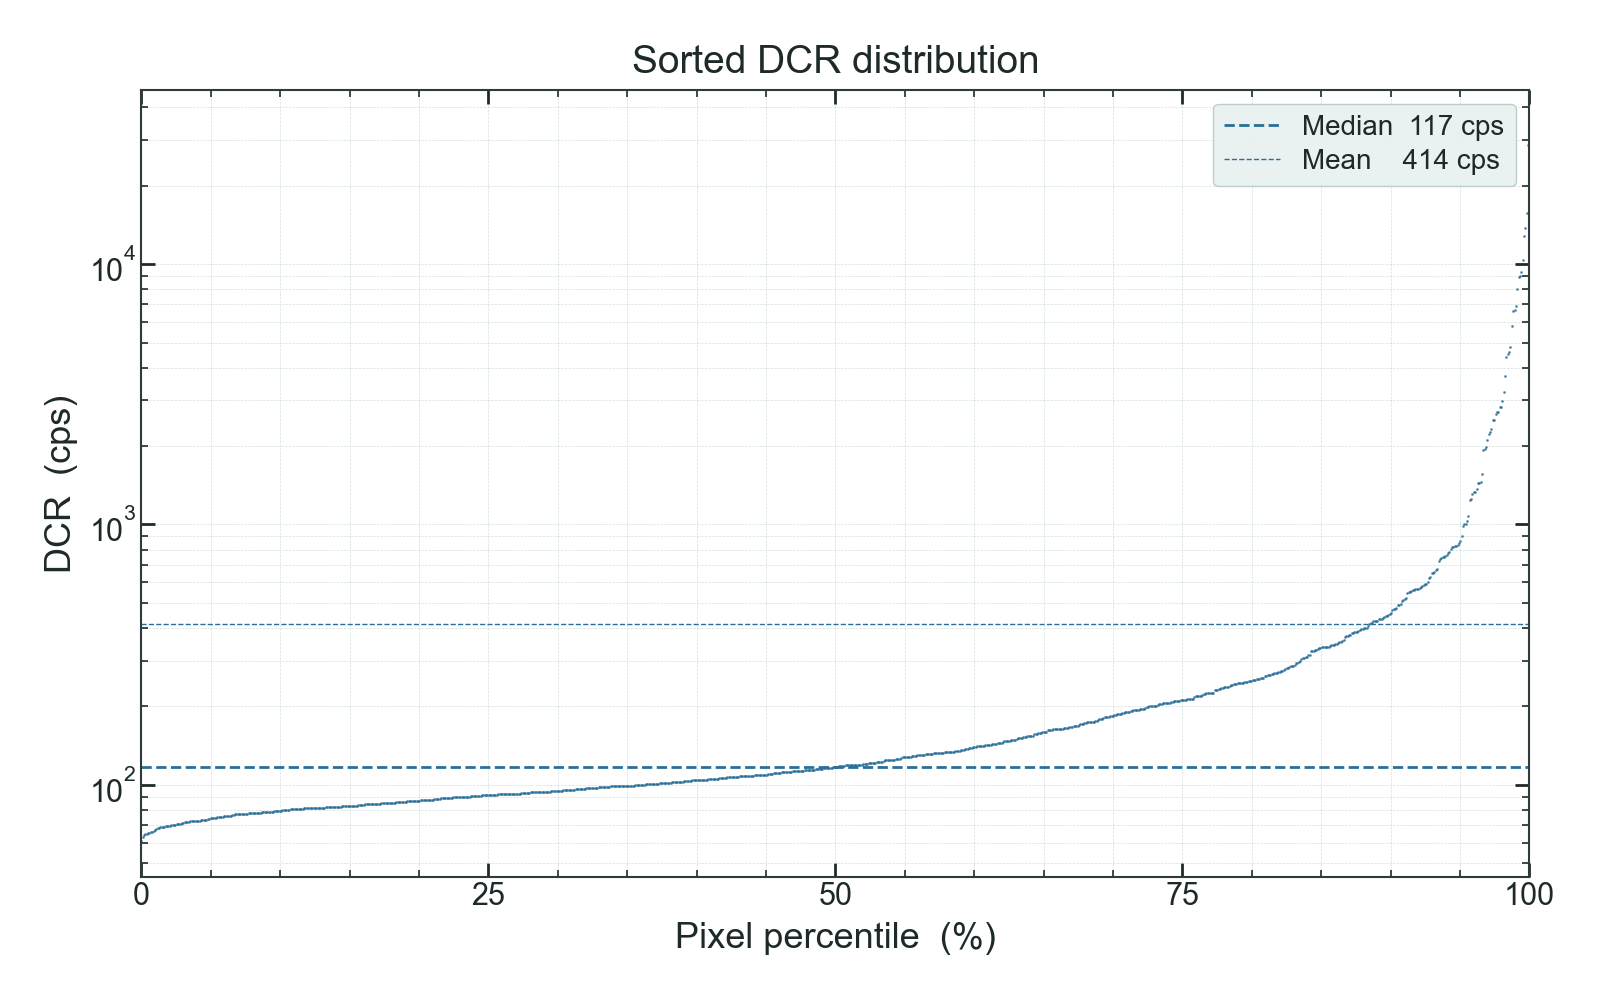

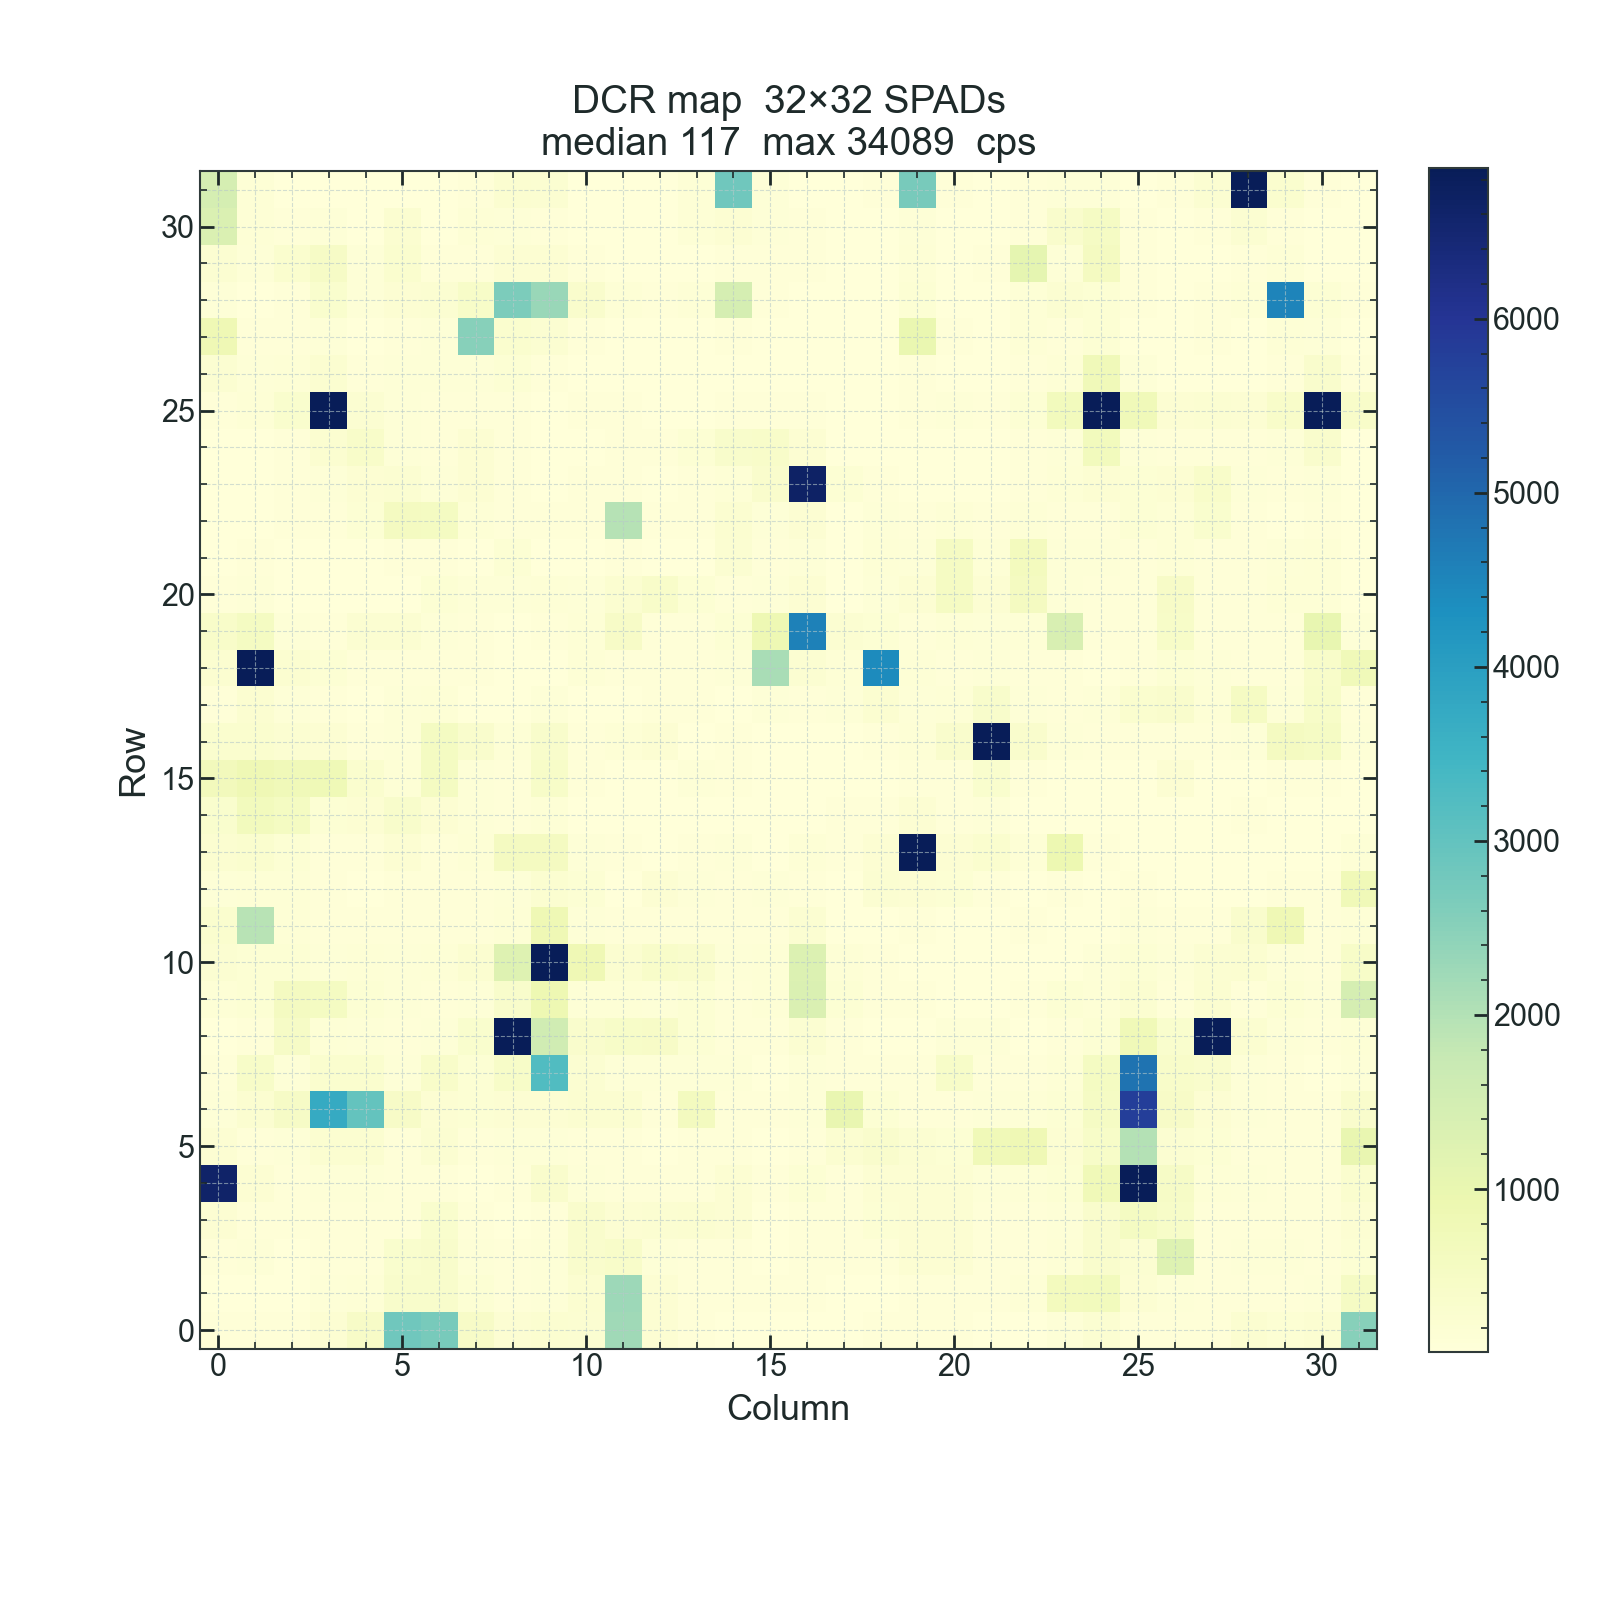

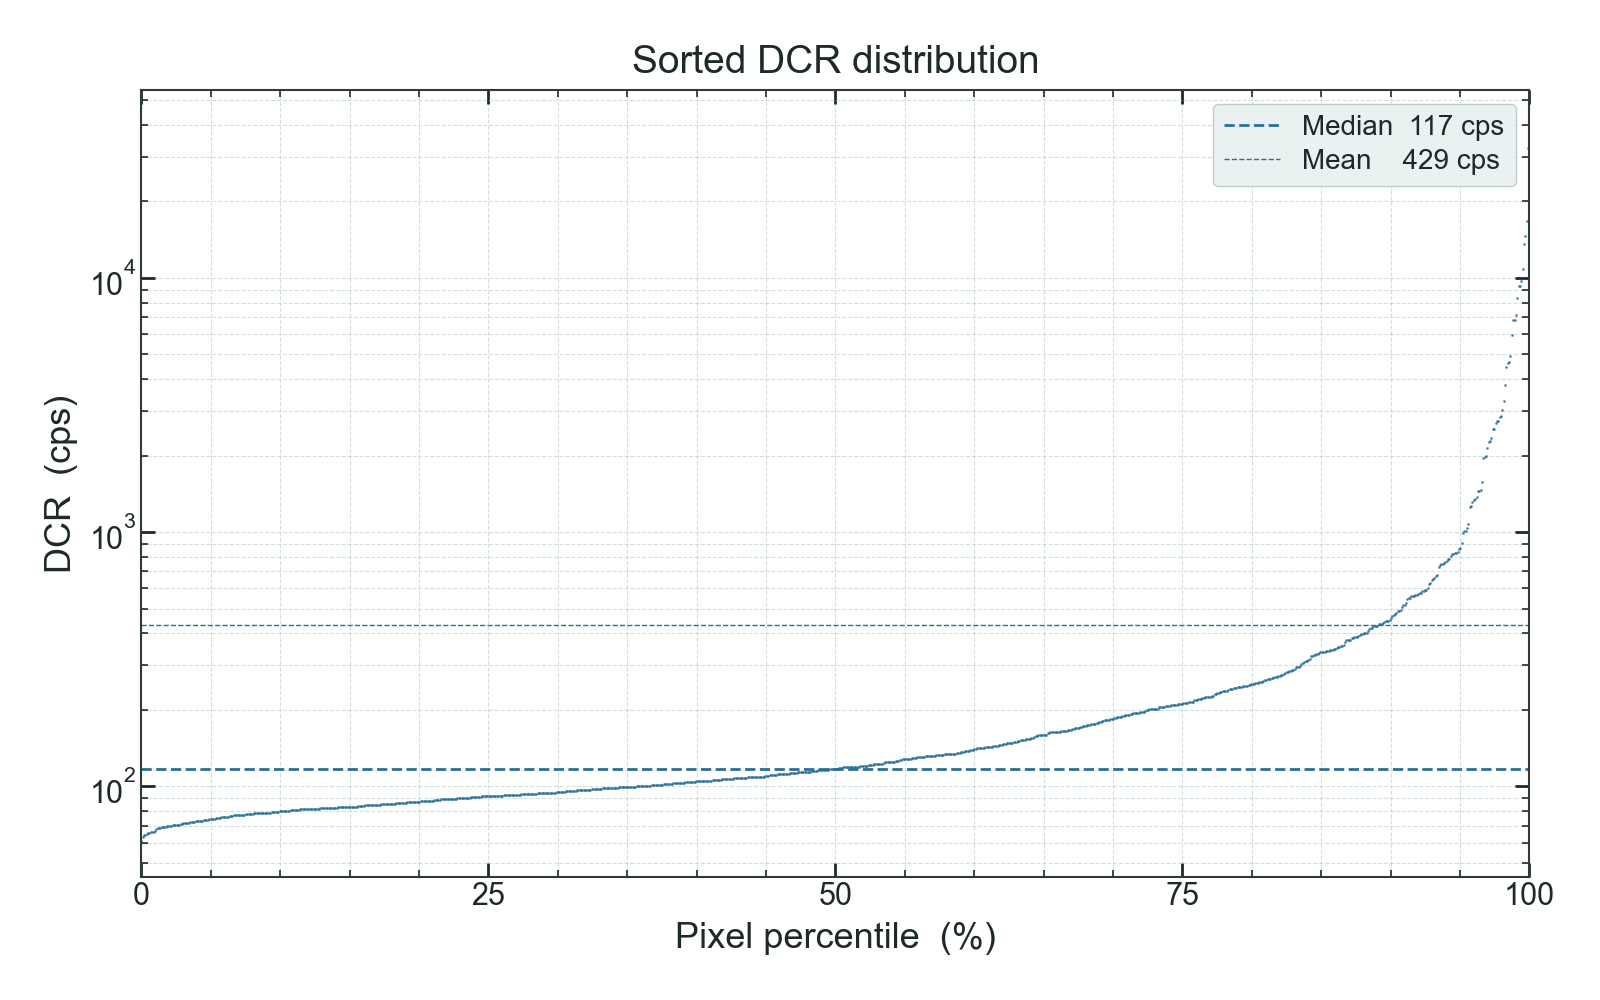

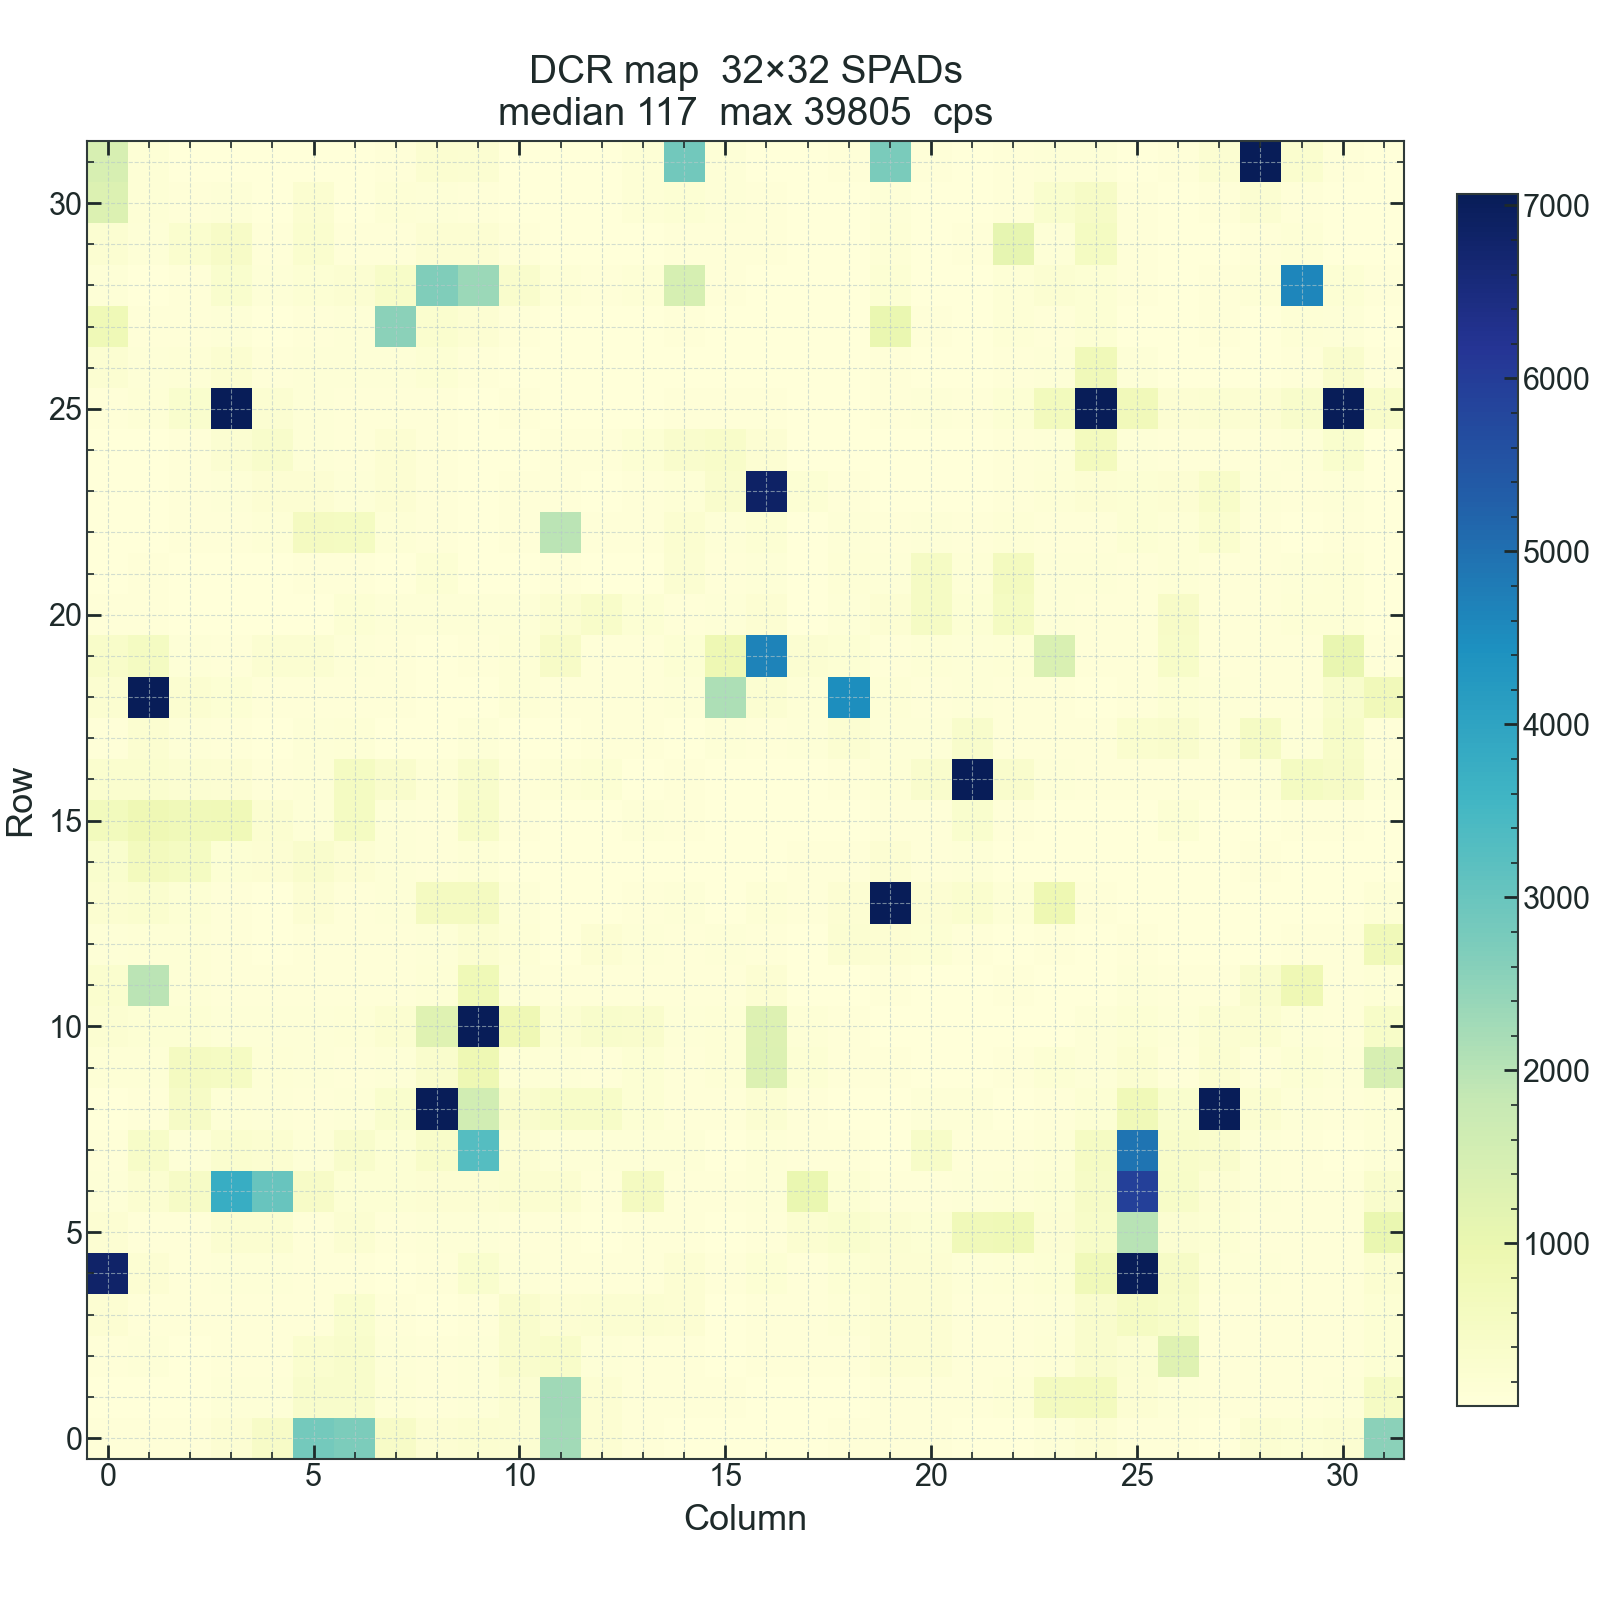

In [7]:
tag = "S0T"
dcr_analysis.process_dcr(
    path, nframes, tag, open_shutter_time_s=8e-6, pileup_correct=True
)
dcr_t = dcr_analysis.plot_dcr(path, tag)
show_figures(path, "dcr")

Counting mode (`...C`) has no ceiling and ignores the flag.

## 6. Load a saved map later

Everything the plot needs is in `processed/`:

In [9]:
from dapkel.core import store

dcr, meta = store.load_map(path, kind="dcr", tag=tag)
print(meta["frame_live_s"], meta["firmware_version"], meta["n_files"])

8e-06 short_exposure 100
